# 03 · Cross-exchange BTC/USDT and a constant-product AMM

Module **M4: CEX, DEX and custody**.

**Questions.**

- **(a)** The "same" BTC/USDT trades on Binance, OKX and Bybit. Minute by minute, how far apart
  are their prices on a calm week, and on one stress night (2025-10-10, the night USDe lost its
  peg on Binance)? How often is the gap bigger than a rough cost band, and for how long?
- **(b)** On a DEX pool that follows `x · y = k`, how much worse than the spot price do you pay
  as your order gets bigger, and how does pool depth change that?

**Hypothesis (lab rule 1).** *I believe the three prices stay within a few bps of each other in
calm markets, because arbitrageurs buy on the cheap venue and sell on the expensive one whenever the
gap is larger than their costs. I believe the gap widens under stress, because the costs and risks
of arbitrage grow (wider spreads, thinner books, slower and riskier movement of funds), so a wider
gap can survive.*

**Glossary (new terms).**

- **CEX** (centralized exchange): a company that runs an **order book** (a list of buy and sell
  offers) and holds your funds (custody).
- **DEX / AMM** (decentralized exchange / automated market maker): a smart contract **pool** with
  two tokens; a formula, not an order book, sets the price.
- **bps** (basis point): 0.01%. 20 bps = 0.20%.
- **Taker fee**: the fee you pay when your order executes immediately against the book.
- **Spread**: the gap between the best buy offer (bid) and the best sell offer (ask).
- **Arbitrage**: buying where it is cheap and selling where it is expensive at (almost) the same
  time. It only pays when the gap is larger than all its costs.
- **Price impact**: how much worse your average price is than the price before your trade,
  caused by your own order eating the liquidity.
- **Slippage**: the difference between the price you expected and the one you got, because
  the market moved between sending and executing the order. It is **not** the same as impact.
- **Filled candle**: a minute with no trades that an exchange still reports, with volume 0 and
  O = H = L = C = previous close (seen on Bitstamp in notebook 02).
- **Gap** (in the data): a minute for which the exchange sends no candle at all.

## 1. Setup and parameters

**Parameters fixed before looking at the data** (lab rule 4). If any of them changes after
inspection, it is labeled as a post-inspection change.

- Exchanges: **Binance** (reference), **OKX**, **Bybit**; pair **BTC/USDT spot**, 1-minute candles,
  public data through ccxt (no API key).
- Windows (UTC, start included, end excluded):
  - **calm**: 2026-11-02 00:00 → 2026-11-09 00:00 (7 days);
  - **stress (10/10)**: 2025-10-10 18:00 → 2025-10-11 06:00 (12 hours). USDe's de-peg on Binance
    ran from about 21:36 to 22:16 UTC.
- Price: the `close` of each minute. Difference vs Binance in bps: `(P_ex / P_binance − 1) × 10,000`.
- Threshold: **20 bps**, about two taker fees of 0.10% (one to buy, one to sell). It is a rough
  stand-in for the cost band, not the real band of each exchange (no spread, no withdrawal fees,
  no VIP discounts).
- Main metrics use only minutes **present on all three exchanges with volume > 0 on all three**.
  Sensitivity: the same metrics including filled candles (if any exist).

In [1]:
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.amm import quote_reserve_for_impact, swap_quote_for_base
from src.cross_exchange import (common_minutes, coverage_report, pairwise_diffs, runs_above,
                                summarize_diff)
from src.data.bitstamp import load_or_fetch_json
from src.data.candles import to_utc
from src.data.ohlcv import (EXCHANGE_MAX_LIMIT, fetch_ohlcv_window, fetch_page_with_retry,
                            first_available_candle, load_or_fetch_window, make_exchange,
                            measure_max_page)

SYMBOL = "BTC/USDT"
EXCHANGES = ["binance", "okx", "bybit"]
REFERENCE = "binance"
PAIRS = [("okx", "binance"), ("bybit", "binance"), ("bybit", "okx")]
WINDOWS = {
    "calm": (to_utc("2026-11-02 00:00"), to_utc("2026-11-09 00:00")),
    "stress": (to_utc("2025-10-10 18:00"), to_utc("2025-10-11 06:00")),
}
USDE_DEPEG = (to_utc("2025-10-10 21:36"), to_utc("2025-10-10 22:16"))  # Binance USDe, approx.
THRESHOLD_BPS = 20.0
CACHE_DIR = REPO_ROOT / "data" / "raw" / "03_cross_exchange_and_amm"

# Categorical colors, fixed per exchange (never by rank).
COLORS = {"binance": "#2a78d6", "okx": "#eb6834", "bybit": "#1baf7a"}
PAIR_COLORS = {"okx vs binance": COLORS["okx"], "bybit vs binance": COLORS["bybit"],
               "bybit vs okx": "#6250d6"}
GRAY = "#8a8987"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})
pd.set_option("display.width", 140)

## 2. Step 0 · Check the sources before downloading everything

The documentation (read on 2026-11-15) says:

| Exchange | Endpoint | Max per request (docs) | Time params | Order (raw API) |
|---|---|---|---|---|
| Binance | `GET /api/v3/klines` | 1000 (default 500) | `startTime`/`endTime` in ms (µs also accepted) | oldest first |
| Bybit | `GET /v5/market/kline`, `category=spot` | 1000 (default 200) | `start`/`end` in ms | newest first |
| OKX | `GET /api/v5/market/candles`, `history-candles` | 100 or 300 (sources disagree) | `after`/`before`, exclusive, paginate backwards | newest first |

Documentation can be outdated, and ccxt adds its own layer on top of the raw API. So we
**measure** with small requests. The results are cached in `data/` (so re-running the notebook does
not hit the APIs again); delete the cache file to measure again.

What each column means:

- `max page (asked → got)`: we ask for 100, 300, 1000 and 1500 candles and count what comes back.
  An exchange that caps silently returns the same number for every bigger ask.
- `default page`: what comes back when we do not send `limit`.
- `raw first timestamp`: the number exactly as sent. 13 digits = **milliseconds** (10 would be
  seconds, 16 microseconds). We parse it with `unit="ms"` and check the date is the one we asked for.
- `oldest first`: order of the candles **as ccxt returns them**.
- `first 1m candle`: the oldest BTC/USDT 1-minute candle the exchange serves.
- `last candle still forming`: whether the newest candle's minute has not ended yet. If so, its
  close/high/low/volume are not final, and our download drops it.

In [2]:
def check_source(exchange_id):
    # One small set of requests per exchange. Errors (e.g. HTTP 451 region block) are reported.
    try:
        ex = make_exchange(exchange_id)
        start_ms = int(WINDOWS["stress"][0].timestamp() * 1000)
        caps = measure_max_page(ex, SYMBOL, start_ms, asks=(100, 300, 1000, 1500, None))
        page = fetch_page_with_retry(ex, SYMBOL, "1m", start_ms, 300)
        stamps = [row[0] for row in page]
        first_ms = first_available_candle(ex, SYMBOL, int(to_utc("2017-01-01").timestamp() * 1000),
                                          int(to_utc("2022-01-01").timestamp() * 1000))
        now_ms = ex.milliseconds()
        newest = fetch_page_with_retry(ex, SYMBOL, "1m", None, 3)[-1][0]
        return {
            "access": "ok",
            "max page (asked → got)": ", ".join(f"{k}→{v}" for k, v in caps.items() if k),
            "default page": caps[None],
            "raw first timestamp": stamps[0],
            "parsed (ms, UTC)": str(pd.to_datetime(stamps[0], unit="ms", utc=True)),
            "oldest first": stamps == sorted(stamps),
            "step (s)": sorted({(b - a) // 1000 for a, b in zip(stamps, stamps[1:])}),
            "first 1m candle (UTC)": str(pd.to_datetime(first_ms, unit="ms", utc=True)),
            "last candle still forming": newest + 60_000 > now_ms,
            "checked at (UTC)": str(pd.to_datetime(now_ms, unit="ms", utc=True).floor("s")),
        }
    except Exception as error:  # report, do not hide
        return {"access": f"{type(error).__name__}: {str(error)[:120]}"}


source_checks = load_or_fetch_json(CACHE_DIR / "source_checks.json",
                                   lambda: {ex: check_source(ex) for ex in EXCHANGES})
pd.DataFrame(source_checks).T

,access,max page (asked → got),default page,raw first timestamp,"parsed (ms, UTC)",oldest first,step (s),first 1m candle (UTC),last candle still forming,checked at (UTC)
binance,ok,"100→100, 300→300, 1000→1000, 1500→1000",500,1760119200000,2025-10-10 18:00:00+00:00,True,[60],2017-08-17 04:00:00+00:00,True,2026-11-15 19:11:47+00:00
okx,ok,"100→100, 300→300, 1000→300, 1500→300",100,1760119200000,2025-10-10 18:00:00+00:00,True,[60],2018-01-11 11:12:00+00:00,True,2026-11-15 19:11:56+00:00
bybit,ok,"100→100, 300→300, 1000→1000, 1500→1000",200,1760119200000,2025-10-10 18:00:00+00:00,True,[60],2021-07-05 12:00:00+00:00,True,2026-11-15 19:12:10+00:00


Two more facts were checked once, by hand, while preparing this notebook (2026-11-15, ccxt 4.5.92):

- **ccxt does not paginate on its own.** One call returns at most one page. Its optional
  `params={"paginate": True}` returned candles from the wrong dates on Binance (it ignored `since`),
  so we paginate by hand: each new request starts at the last timestamp received + 1 ms, using the
  measured page size per exchange (`EXCHANGE_MAX_LIMIT` in `src/data/ohlcv.py`).
- **Bybit quirk:** asking for `since=0` returns the *latest* candles instead of the oldest, and
  **OKX** returns an empty page when asked for dates before its history starts. That is why
  `first_available_candle` starts from a real date and bisects when the answer is empty.
- **`since` is inclusive** in ccxt for all three, so overlapping requests produce duplicates. The
  download removes identical duplicates and **raises an error** if one timestamp comes with two
  different candles.
- **Errors:** the client uses `enableRateLimit=True`; temporary errors (429 rate limit, time-outs,
  5xx) are retried with exponential backoff (1 s, 2 s, 4 s, …); 451/403 (region block) are not
  retried, because waiting does not fix them.

## 3. Download, coverage and quality

For each exchange and window, `fetch_ohlcv_window` downloads the candles with open time in
`[start, end)`, removes duplicates and the candle still forming, and **never fills a gap**.
The table counts, per exchange and window:

- `expected`: minutes in the window; `present`: candles received;
- `gaps`: minutes with no candle at all;
- `filled (vol 0)`: candles with volume 0, and how many of those repeat the previous close (O=H=L=C);
- `duplicates dropped`: repeated identical candles removed during pagination;
- `volume (BTC)`: total traded volume. ccxt reports volume in the **base** currency (BTC here).

In [3]:
frames, infos = {}, {}
for window, (start, end) in WINDOWS.items():
    for ex_id in EXCHANGES:
        path = CACHE_DIR / f"{ex_id}_BTCUSDT_1m_{window}.parquet"
        frames[window, ex_id], infos[window, ex_id] = load_or_fetch_window(
            path, lambda: fetch_ohlcv_window(ex_id, SYMBOL, start, end))

# Hard checks on exactly what we analyze. Any failure stops the notebook.
for (window, ex_id), df in frames.items():
    start, end = WINDOWS[window]
    assert str(df.index.tz) == "UTC", (window, ex_id)
    assert df.index.is_unique and df.index.is_monotonic_increasing, (window, ex_id)
    assert (df.index == df.index.floor("1min")).all(), (window, ex_id)
    assert df.index.min() >= start and df.index.max() < end, (window, ex_id)
    assert (df[["open", "high", "low", "close"]] > 0).all().all(), (window, ex_id)
    assert (df["high"] >= df[["open", "close", "low"]].max(axis=1)).all(), (window, ex_id)

coverage = pd.DataFrame({
    (window, ex_id): coverage_report(df, *WINDOWS[window], infos[window, ex_id])
    for (window, ex_id), df in frames.items()
}).T
coverage.index.names = ["window", "exchange"]
coverage = coverage.rename(columns={"filled_vol0": "filled (vol 0)",
                                    "filled_flat_prev_close": "…of which O=H=L=C=prev close",
                                    "duplicates_dropped": "duplicates dropped",
                                    "volume_base": "volume (BTC)"})
counts = coverage.columns.drop("volume (BTC)")
coverage[counts] = coverage[counts].astype(int)
coverage["volume (BTC)"] = coverage["volume (BTC)"].astype(float).round(0)
coverage

expected  present  gaps  filled (vol 0)  …of which O=H=L=C=prev close  duplicates dropped  volume (BTC)
window exchange                                                                                                         
calm   binance      10080    10080     0               0                             0                   0      105282.0
       okx          10080    10080     0               0                             0                   0       54024.0
       bybit        10080    10080     0               0                             0                   0       78396.0
stress binance        720      720     0               0                             0                   0       60154.0
       okx            720      720     0               0                             0                   0       22253.0
       bybit          720      720     0               0                             0                   0       28015.0

## 4. Part (a) · The same BTC/USDT on three exchanges

### 4.1 Aligning the minutes

Each `close` belongs to one exchange. We put them side by side **only on minutes that exist
on all three with volume > 0** (main), and, as sensitivity, on minutes that exist on all three
regardless of volume (this adds filled candles, if any). Nothing is filled or shifted: each close
stays on its own minute.

In [4]:
closes, closes_sens = {}, {}
for window in WINDOWS:
    window_frames = {ex_id: frames[window, ex_id] for ex_id in EXCHANGES}
    main_idx = common_minutes(window_frames, require_volume=True)
    sens_idx = common_minutes(window_frames, require_volume=False)
    closes[window] = pd.DataFrame({ex: window_frames[ex].loc[main_idx, "close"] for ex in EXCHANGES})
    closes_sens[window] = pd.DataFrame({ex: window_frames[ex].loc[sens_idx, "close"]
                                        for ex in EXCHANGES})

pd.DataFrame({window: {"minutes in window": len(pd.date_range(*WINDOWS[window], freq="1min",
                                                                inclusive="left")),
                       "main: on all 3, volume > 0": len(closes[window]),
                       "sensitivity: on all 3, any volume": len(closes_sens[window])}
              for window in WINDOWS})

,calm,stress
minutes in window,10080,720
"main: on all 3, volume > 0",10080,720
"sensitivity: on all 3, any volume",10080,720


### 4.2 Prices during the stress window

Top: the three closes over the whole 12-hour stress window. Bottom: a zoom of ±45 minutes around
the minute where Binance's close was lowest. The shaded band is the approximate USDe de-peg on
Binance (21:36–22:16 UTC). Each point is the last trade of that minute **on that exchange**.

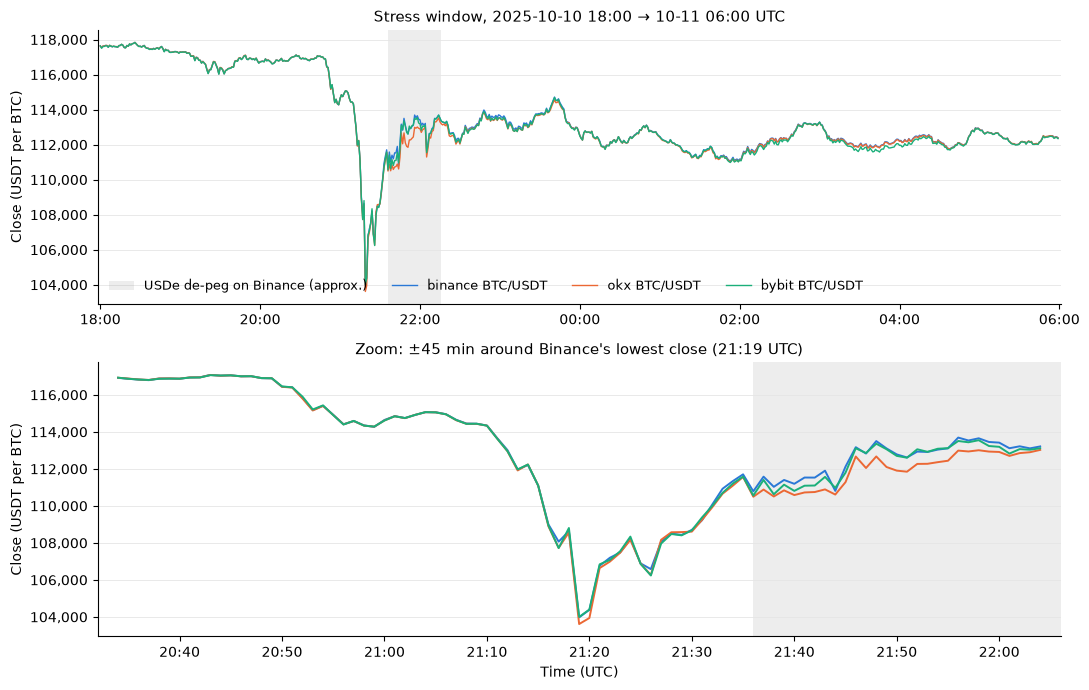

,binance,okx,bybit
Binance's lowest close (UTC),,,
2025-10-10 21:19:00+00:00,103975.26,103615.1,104000.1


In [5]:
stress = closes["stress"]
t_min = stress[REFERENCE].idxmin()
zoom = stress.loc[t_min - pd.Timedelta(minutes=45): t_min + pd.Timedelta(minutes=45)]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, data, title in [(axes[0], stress, "Stress window, 2025-10-10 18:00 → 10-11 06:00 UTC"),
                        (axes[1], zoom, f"Zoom: ±45 min around Binance's lowest close ({t_min:%H:%M} UTC)")]:
    ax.axvspan(*USDE_DEPEG, color=GRAY, alpha=0.15, linewidth=0, label="USDe de-peg on Binance (approx.)")
    for ex_id in EXCHANGES:
        ax.plot(data.index, data[ex_id], color=COLORS[ex_id], linewidth=1.4 if ax is axes[1] else 1.0,
                label=f"{ex_id} BTC/USDT")
    ax.set_title(title)
    ax.set_ylabel("Close (USDT per BTC)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
    ax.set_xlim(data.index.min() - pd.Timedelta(minutes=2), data.index.max() + pd.Timedelta(minutes=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
axes[0].legend(loc="lower left", ncols=4, fontsize=9)
axes[1].set_xlabel("Time (UTC)")
fig.tight_layout()
plt.show()

stress.loc[[t_min]].rename_axis("Binance's lowest close (UTC)")

### 4.3 Difference vs Binance over time

Each line is `(P_ex / P_binance − 1) × 10,000` in bps, minute by minute. Above zero, that exchange
was more expensive than Binance in that minute. Dashed lines: ±20 bps threshold. The two panels
have **different y-scales** (same unit) because the stress gaps are much larger; the threshold
lines are drawn in both.

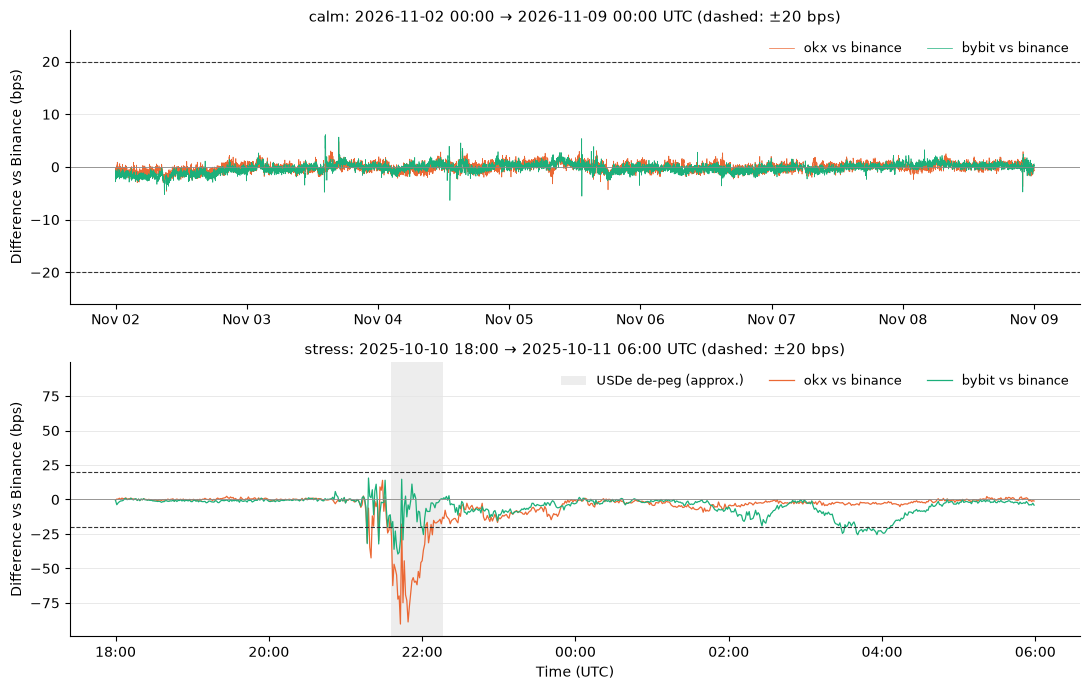

In [6]:
diffs = {window: pairwise_diffs(closes[window], PAIRS) for window in WINDOWS}
diffs_sens = {window: pairwise_diffs(closes_sens[window], PAIRS) for window in WINDOWS}
vs_ref = [f"{a} vs {b}" for a, b in PAIRS if b == REFERENCE]

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, window in zip(axes, WINDOWS):
    d = diffs[window][vs_ref]
    if window == "stress":
        ax.axvspan(*USDE_DEPEG, color=GRAY, alpha=0.15, linewidth=0, label="USDe de-peg (approx.)")
    for col in vs_ref:
        ax.plot(d.index, d[col], color=PAIR_COLORS[col], linewidth=0.5 if window == "calm" else 0.9,
                label=col)
    for level in (THRESHOLD_BPS, -THRESHOLD_BPS):
        ax.axhline(level, color="#333333", linestyle="--", linewidth=0.8)
    ax.axhline(0, color=GRAY, linewidth=0.6)
    lim = max(THRESHOLD_BPS * 1.3, d.abs().max().max() * 1.1)
    ax.set_ylim(-lim, lim)
    ax.set_ylabel("Difference vs Binance (bps)")
    ax.set_title(f"{window}: {WINDOWS[window][0]:%Y-%m-%d %H:%M} → {WINDOWS[window][1]:%Y-%m-%d %H:%M} UTC"
                 f" (dashed: ±{THRESHOLD_BPS:.0f} bps)")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
    ax.legend(loc="upper right", ncols=3, fontsize=9)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d", tz="UTC"))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz="UTC"))
axes[1].set_xlabel("Time (UTC)")
fig.tight_layout()
plt.show()

### 4.4 Summary per window and pair

For each pair `a vs b` (difference of `a` relative to `b`, in bps):

- `median (bps)`: the typical signed gap; negative means `a` is usually cheaper than `b`;
- `p95 |diff|`: 95% of minutes have an absolute gap at or below this;
- `max |diff|` and the minute it happened;
- `% min > 20 bps` and the count of those minutes;
- `longest run (min)`: the longest streak of **consecutive** minutes above the threshold
  (a missing minute ends a streak).

In [7]:
def summary_table(diff_by_window):
    rows = {(window, pair): summarize_diff(d[pair], THRESHOLD_BPS)
            for window, d in diff_by_window.items() for pair in d.columns}
    table = pd.DataFrame(rows).T
    table.index.names = ["window", "pair"]
    table = table.rename(columns={"median_bps": "median (bps)", "p95_abs_bps": "p95 |diff| (bps)",
                                  "max_abs_bps": "max |diff| (bps)", "max_at_utc": "max at (UTC)",
                                  "pct_above": f"% min > {THRESHOLD_BPS:.0f} bps",
                                  "minutes_above": f"min > {THRESHOLD_BPS:.0f} bps",
                                  "longest_run_min": "longest run (min)"})
    for col in ["median (bps)", "p95 |diff| (bps)", "max |diff| (bps)", f"% min > {THRESHOLD_BPS:.0f} bps"]:
        table[col] = table[col].astype(float).round(2)
    return table


summary = summary_table(diffs)
summary

minutes  median (bps)  p95 |diff| (bps)  max |diff| (bps)               max at (UTC)  % min > 20 bps min > 20 bps  \
window pair                                                                                                                                 
calm   okx vs binance     10080         -0.07              1.62              4.80  2026-11-03 16:50:00+00:00            0.00            0   
       bybit vs binance   10080         -0.16              1.85              6.35  2026-11-04 13:09:00+00:00            0.00            0   
       bybit vs okx       10080         -0.14              1.31              6.11  2026-11-03 14:25:00+00:00            0.00            0   
stress okx vs binance       720         -1.95             18.54             90.32  2025-10-10 21:43:00+00:00            4.86           35   
       bybit vs binance     720         -2.21             20.89             39.59  2025-10-10 21:41:00+00:00            5.69           41   
       bybit vs okx         720         -0.73             20.53             85.66  2025-10-10 21:49:00+00:00            5.69           41   

                        longest run (min)  
window pair                                
calm   okx vs binance                   0  
       bybit vs binance                 0  
       bybit vs okx                     0  
stress okx vs binance                  18  
       bybit vs binance                27  
       bybit vs okx                    22

**Sensitivity: including filled candles.** Same table on minutes present on all three exchanges
with any volume. The second output shows the cell-by-cell difference vs the main table (all
zeros means the filter changed nothing).

In [8]:
summary_sens = summary_table(diffs_sens)
numeric = summary.columns.drop("max at (UTC)")
display(summary_sens)
(summary_sens[numeric].astype(float) - summary[numeric].astype(float)).round(2)

minutes  median (bps)  p95 |diff| (bps)  max |diff| (bps)               max at (UTC)  % min > 20 bps min > 20 bps  \
window pair                                                                                                                                 
calm   okx vs binance     10080         -0.07              1.62              4.80  2026-11-03 16:50:00+00:00            0.00            0   
       bybit vs binance   10080         -0.16              1.85              6.35  2026-11-04 13:09:00+00:00            0.00            0   
       bybit vs okx       10080         -0.14              1.31              6.11  2026-11-03 14:25:00+00:00            0.00            0   
stress okx vs binance       720         -1.95             18.54             90.32  2025-10-10 21:43:00+00:00            4.86           35   
       bybit vs binance     720         -2.21             20.89             39.59  2025-10-10 21:41:00+00:00            5.69           41   
       bybit vs okx         720         -0.73             20.53             85.66  2025-10-10 21:49:00+00:00            5.69           41   

                        longest run (min)  
window pair                                
calm   okx vs binance                   0  
       bybit vs binance                 0  
       bybit vs okx                     0  
stress okx vs binance                  18  
       bybit vs binance                27  
       bybit vs okx                    22

minutes  median (bps)  p95 |diff| (bps)  max |diff| (bps)  % min > 20 bps  min > 20 bps  longest run (min)
window pair                                                                                                                        
calm   okx vs binance        0.0           0.0               0.0               0.0             0.0           0.0                0.0
       bybit vs binance      0.0           0.0               0.0               0.0             0.0           0.0                0.0
       bybit vs okx          0.0           0.0               0.0               0.0             0.0           0.0                0.0
stress okx vs binance        0.0           0.0               0.0               0.0             0.0           0.0                0.0
       bybit vs binance      0.0           0.0               0.0               0.0             0.0           0.0                0.0
       bybit vs okx          0.0           0.0               0.0               0.0             0.0           0.0                0.0

### 4.5 Are the stress numbers driven by a few minutes?

The "% of minutes above 20 bps" over 12 hours can hide whether the gap was open in one long
episode or in many separate blips. This table lists every run of consecutive minutes above the
threshold in the stress window (first and last minute, length, largest |diff| and its sign).

In [9]:
runs = pd.concat({pair: runs_above(diffs["stress"][pair], THRESHOLD_BPS) for pair in diffs["stress"]},
                 names=["pair", "run"])
runs["max_abs_bps"] = runs["max_abs_bps"].astype(float).round(1)
runs["signed_at_max_bps"] = runs["signed_at_max_bps"].astype(float).round(1)
runs

first_utc                  last_utc  minutes  max_abs_bps  signed_at_max_bps
pair             run                                                                                             
okx vs binance   0   2025-10-10 21:17:00+00:00 2025-10-10 21:17:00+00:00        1         31.3              -31.3
                 1   2025-10-10 21:19:00+00:00 2025-10-10 21:20:00+00:00        2         42.4              -42.4
                 2   2025-10-10 21:26:00+00:00 2025-10-10 21:26:00+00:00        1         29.9              -29.9
                 3   2025-10-10 21:33:00+00:00 2025-10-10 21:34:00+00:00        2         24.3              -24.3
                 4   2025-10-10 21:36:00+00:00 2025-10-10 21:43:00+00:00        8         90.3              -90.3
                 5   2025-10-10 21:45:00+00:00 2025-10-10 22:02:00+00:00       18         88.8              -88.8
                 6   2025-10-10 22:05:00+00:00 2025-10-10 22:06:00+00:00        2         31.4              -31.4
                 7   2025-10-10 22:08:00+00:00 2025-10-10 22:08:00+00:00        1         25.6              -25.6
bybit vs binance 0   2025-10-10 21:17:00+00:00 2025-10-10 21:17:00+00:00        1         32.0              -32.0
                 1   2025-10-10 21:26:00+00:00 2025-10-10 21:26:00+00:00        1         32.2              -32.2
                 2   2025-10-10 21:36:00+00:00 2025-10-10 21:36:00+00:00        1         20.7              -20.7
                 3   2025-10-10 21:38:00+00:00 2025-10-10 21:43:00+00:00        6         39.6              -39.6
                 4   2025-10-10 21:45:00+00:00 2025-10-10 21:45:00+00:00        1         29.3              -29.3
                 5   2025-10-10 22:01:00+00:00 2025-10-10 22:01:00+00:00        1         25.5              -25.5
                 6   2025-10-11 03:28:00+00:00 2025-10-11 03:30:00+00:00        3         24.6              -24.6
                 7   2025-10-11 03:40:00+00:00 2025-10-11 04:06:00+00:00       27         25.6              -25.6
bybit vs okx     0   2025-10-10 21:18:00+00:00 2025-10-10 21:20:00+00:00        3         43.8               43.8
                 1   2025-10-10 21:37:00+00:00 2025-10-10 21:37:00+00:00        1         46.8               46.8
                 2   2025-10-10 21:39:00+00:00 2025-10-10 22:00:00+00:00       22         85.7               85.7
                 3   2025-10-10 22:05:00+00:00 2025-10-10 22:05:00+00:00        1         22.8               22.8
                 4   2025-10-10 22:08:00+00:00 2025-10-10 22:08:00+00:00        1         23.2               23.2
                 5   2025-10-11 03:29:00+00:00 2025-10-11 03:30:00+00:00        2         22.4              -22.4
                 6   2025-10-11 03:40:00+00:00 2025-10-11 03:41:00+00:00        2         22.3              -22.3
                 7   2025-10-11 03:43:00+00:00 2025-10-11 03:43:00+00:00        1         20.3              -20.3
                 8   2025-10-11 03:45:00+00:00 2025-10-11 03:45:00+00:00        1         21.1              -21.1
                 9   2025-10-11 03:48:00+00:00 2025-10-11 03:48:00+00:00        1         20.2              -20.2
                 10  2025-10-11 03:55:00+00:00 2025-10-11 03:56:00+00:00        2         22.1              -22.1
                 11  2025-10-11 04:00:00+00:00 2025-10-11 04:03:00+00:00        4         22.2              -22.2

### 4.6 Volume per exchange

Traded volume in each window: total BTC, its share of the three-exchange total, and the median
per minute in BTC and in USDT (volume × close of the same minute). Volume reported by an exchange
is not audited; we use it only to compare sizes.

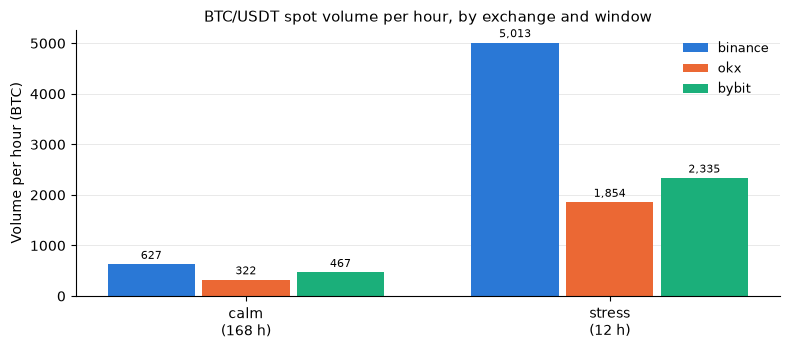

total (BTC)  share of 3 (%)  per hour (BTC)  median per minute (BTC)  median per minute (USDT)
window exchange                                                                                                
calm   binance      105282.0            44.3           627.0                     5.42                  420766.0
       okx           54024.0            22.7           322.0                     2.06                  159229.0
       bybit         78396.0            33.0           467.0                     5.24                  405853.0
stress binance       60154.0            54.5          5013.0                    40.57                 4605270.0
       okx           22253.0            20.2          1854.0                    13.11                 1485886.0
       bybit         28015.0            25.4          2335.0                    22.57                 2550281.0

In [10]:
vol_rows = {}
for (window, ex_id), df in frames.items():
    vol_rows[window, ex_id] = {"total (BTC)": df["volume"].sum(),
                               "median per minute (BTC)": df["volume"].median(),
                               "median per minute (USDT)": (df["volume"] * df["close"]).median()}
volume = pd.DataFrame(vol_rows).T
volume.index.names = ["window", "exchange"]
volume.insert(1, "share of 3 (%)", 100 * volume["total (BTC)"]
              / volume.groupby(level="window")["total (BTC)"].transform("sum"))
hours = {w: (e - s) / pd.Timedelta(hours=1) for w, (s, e) in WINDOWS.items()}
volume.insert(2, "per hour (BTC)", [volume.loc[(w, ex), "total (BTC)"] / hours[w] for w, ex in volume.index])

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(WINDOWS))
width = 0.26
for i, ex_id in enumerate(EXCHANGES):
    vals = [volume.loc[(w, ex_id), "per hour (BTC)"] for w in WINDOWS]
    bars = ax.bar(x + (i - 1) * width, vals, width - 0.02, color=COLORS[ex_id], label=ex_id)
    ax.bar_label(bars, fmt="{:,.0f}", fontsize=8, padding=2)
ax.set_xticks(x, [f"{w}\n({hours[w]:.0f} h)" for w in WINDOWS])
ax.set_ylabel("Volume per hour (BTC)")
ax.set_axisbelow(True)
ax.set_title("BTC/USDT spot volume per hour, by exchange and window")
ax.legend(fontsize=9)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
fig.tight_layout()
plt.show()
volume.round({"total (BTC)": 0, "share of 3 (%)": 1, "per hour (BTC)": 0,
              "median per minute (BTC)": 2, "median per minute (USDT)": 0})

## 5. Part (b) · A constant-product AMM, `x · y = k`

`src/amm.py` (tests in `tests/test_amm.py`). A pool holds `x` ETH and `y` USDC. You put in `Δy`
USDC and take out `Δx` ETH so that `(x − Δx)(y + Δy) = k` stays true:

$$\Delta x = \frac{x\,\Delta y}{y + \Delta y} \quad (\text{always} < x)$$

- spot price before: `y / x`; average price you pay: `Δy / Δx`;
- **impact** = `avg price / spot − 1`. Without fee it equals exactly `Δy / y`;
- **pool price change** = `new price / spot − 1`, the move the *next* trader sees (≈ 2 × impact
  for small orders);
- with fee `f`, only `Δy (1 − f)` enters the formula; a tiny order still pays about `f / (1 − f)`.

Worked example (the one in the tests): pool 100 ETH / 300,000 USDC, order 30,000 USDC.

In [11]:
X0, Y0, ORDER = 100.0, 300_000.0, 30_000.0
FEE = 0.003  # 0.30%, like Uniswap v2
example = pd.DataFrame({
    "no fee": vars(swap_quote_for_base(X0, Y0, ORDER)),
    "fee 0.30%": vars(swap_quote_for_base(X0, Y0, ORDER, fee=FEE)),
}).round(4)
example

,no fee,fee 0.30%
dx_out,9.0909,9.0661
avg_price,3300.0000,3309.0271
spot_before,3000.0000,3000.0000
new_price,3630.0000,3629.0100
impact_pct,10.0000,10.3009
pool_price_change_pct,21.0000,20.9670
x_after,90.9091,90.9339
y_after,330000.0000,330000.0000


### 5.1 Impact vs order size

x-axis: order size as a % of the pool's USDC reserve (`Δy / y`), from 0.01% to 100%, log scale.
y-axis: impact in %, log scale. The dashed line is the theory `Δy / y`; the no-fee curve should
sit exactly on it. The thin gray line is the pool price change (what the next trader faces).

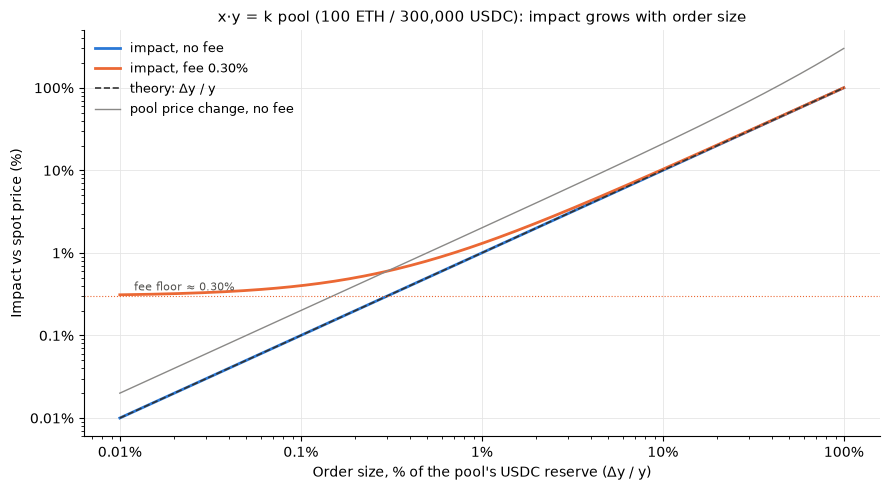

,order (USDC),"impact, no fee (%)","impact, fee 0.30% (%)",pool price change (%)
Δy / y,,,,
0.01%,30.0,0.01,0.3109,0.0200
0.1%,300.0,0.10,0.4009,0.2001
1%,3000.0,1.00,1.3009,2.0100
10%,30000.0,10.00,10.3009,21.0000
100%,300000.0,100.00,100.3009,300.0000


In [12]:
sizes = np.logspace(-4, 0, 200)  # Δy / y from 0.01% to 100%
impact_no_fee = [swap_quote_for_base(X0, Y0, s * Y0).impact_pct for s in sizes]
impact_fee = [swap_quote_for_base(X0, Y0, s * Y0, fee=FEE).impact_pct for s in sizes]
pool_move = [swap_quote_for_base(X0, Y0, s * Y0).pool_price_change_pct for s in sizes]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sizes * 100, impact_no_fee, color=COLORS["binance"], linewidth=2, label="impact, no fee")
ax.plot(sizes * 100, impact_fee, color=COLORS["okx"], linewidth=2, label="impact, fee 0.30%")
ax.plot(sizes * 100, sizes * 100, color="#333333", linestyle="--", linewidth=1.2,
        label="theory: Δy / y")
ax.plot(sizes * 100, pool_move, color=GRAY, linewidth=1, label="pool price change, no fee")
ax.axhline(100 * FEE / (1 - FEE), color=COLORS["okx"], linestyle=":", linewidth=0.8)
ax.annotate("fee floor ≈ 0.30%", (0.012, 100 * FEE / (1 - FEE)), xytext=(0, 4),
            textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Order size, % of the pool's USDC reserve (Δy / y)")
ax.set_ylabel("Impact vs spot price (%)")
ax.set_title(f"x·y = k pool ({X0:.0f} ETH / {Y0:,.0f} USDC): impact grows with order size")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.grid(which="major", color="#e5e5e5", linewidth=0.6)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

marks = [0.0001, 0.001, 0.01, 0.1, 1.0]
pd.DataFrame({
    "order (USDC)": [m * Y0 for m in marks],
    "impact, no fee (%)": [swap_quote_for_base(X0, Y0, m * Y0).impact_pct for m in marks],
    "impact, fee 0.30% (%)": [swap_quote_for_base(X0, Y0, m * Y0, fee=FEE).impact_pct for m in marks],
    "pool price change (%)": [swap_quote_for_base(X0, Y0, m * Y0).pool_price_change_pct for m in marks],
}, index=pd.Index([f"{100 * m:g}%" for m in marks], name="Δy / y")).round(4)

### 5.2 Same order, deeper pools

The same 30,000 USDC order into pools with 1×, 2×, 10× and 100× the reserves of the example
(same spot price 3,000), without fee.

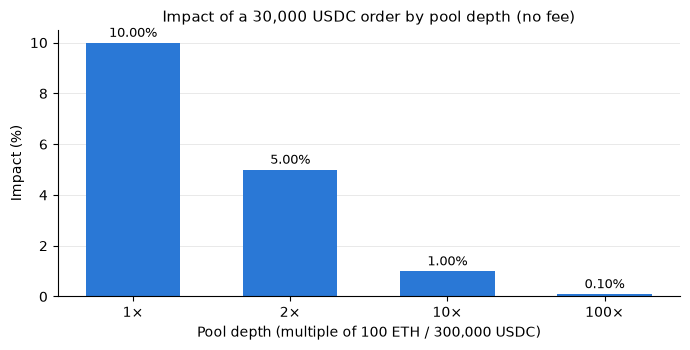

,pool (ETH),pool (USDC),order / USDC reserve (%),"impact, no fee (%)"
depth,,,,
1×,100.0,300000.0,10.0,10.0
2×,200.0,600000.0,5.0,5.0
10×,1000.0,3000000.0,1.0,1.0
100×,10000.0,30000000.0,0.1,0.1


In [13]:
depths = [1, 2, 10, 100]
depth_impact = pd.DataFrame({
    "pool (ETH)": [X0 * m for m in depths],
    "pool (USDC)": [Y0 * m for m in depths],
    "order / USDC reserve (%)": [100 * ORDER / (Y0 * m) for m in depths],
    "impact, no fee (%)": [swap_quote_for_base(X0 * m, Y0 * m, ORDER).impact_pct for m in depths],
}, index=pd.Index([f"{m}×" for m in depths], name="depth"))

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(depth_impact.index, depth_impact["impact, no fee (%)"], color=COLORS["binance"], width=0.6)
ax.bar_label(bars, fmt="{:.2f}%", fontsize=9, padding=2)
ax.set_xlabel("Pool depth (multiple of 100 ETH / 300,000 USDC)")
ax.set_ylabel("Impact (%)")
ax.set_axisbelow(True)
ax.set_title("Impact of a 30,000 USDC order by pool depth (no fee)")
ax.grid(axis="y", color="#e5e5e5", linewidth=0.6)
fig.tight_layout()
plt.show()
depth_impact.round(2)

### 5.3 Bridge to part (a) — descriptive only

How big would an `x · y = k` pool have to be so that an order the size of **one typical calm
minute of Binance BTC/USDT volume** moved the average price by only 20 bps?

Without fee, impact = `Δy / y`, so `y = Δy / 0.002`; the pool holds the same value in BTC, so
its total value is about `2y`. With a 0.30% fee the impact can never be below the fee floor
(≈ 30 bps), so no pool size reaches 20 bps.

**This is an illustration, not a like-for-like comparison.** A CEX order book does not follow
`x · y = k`: liquidity sits at chosen price levels, market makers refill it within seconds, and
the minute's volume is many small trades, not one order.

In [14]:
typical_minute_usdt = volume.loc[("calm", REFERENCE), "median per minute (USDT)"]
y_needed = quote_reserve_for_impact(typical_minute_usdt, THRESHOLD_BPS / 10_000)
btc_price = closes["calm"][REFERENCE].median()
check_no_fee = swap_quote_for_base(y_needed / btc_price, y_needed, typical_minute_usdt)
check_fee = swap_quote_for_base(y_needed / btc_price, y_needed, typical_minute_usdt, fee=FEE)
pd.Series({
    "typical calm minute on Binance (median, USDT)": typical_minute_usdt,
    "BTC/USDT median close, calm (USDT)": btc_price,
    "USDT reserve needed for 20 bps, no fee": y_needed,
    "total pool value ≈ 2 × reserve (USDT)": 2 * y_needed,
    "check: impact in that pool, no fee (%)": check_no_fee.impact_pct,
    "same pool with fee 0.30%: impact (%)": check_fee.impact_pct,
}).map(lambda v: f"{v:,.2f}").to_frame("value")

,value
"typical calm minute on Binance (median, USDT)","420,766.44"
"BTC/USDT median close, calm (USDT)","76,699.07"
"USDT reserve needed for 20 bps, no fee","210,383,220.31"
total pool value ≈ 2 × reserve (USDT),"420,766,440.61"
"check: impact in that pool, no fee (%)",0.20
same pool with fee 0.30%: impact (%),0.50


## 6. Limitations

- **Closes are not simultaneous prices.** Each `close` is the last trade of the minute on that
  exchange, and it can happen at different seconds on each one. In a fast market, part of every
  measured gap is just timing, not a price you could have traded on both venues at once. The
  stress-window gaps are therefore an upper bound on what was really there at a single instant.
- **No USDT vs dollar effect.** All three quote in USDT, so a move of USDT against the dollar is
  invisible here (notebook 02 showed USDT/USD can move).
- **A gap above the threshold is not an arbitrage opportunity.** The 20 bps threshold is only two
  taker fees. Missing: the bid-ask spread (we use last trades, not quotes), the size available in
  the book at that price, the time and fees to move funds between exchanges (or the capital to
  pre-position inventory on both), and counterparty risk of the exchanges themselves.
- **One stress window is n = 1.** One night, chosen because we already knew something happened.
  It shows what *can* happen, not how often.
- **The calm week is one week.** Other calm weeks may differ.
- **One-minute candles** hide what happens inside the minute.
- **Volume is self-reported** by each exchange and not audited.
- **The AMM bridge (5.3) is illustrative.** An order book does not follow `x · y = k`, and one
  minute of volume is not one order.
- **The AMM model ignores** concentrated liquidity (Uniswap v3), gas fees, MEV/sandwich attacks
  and slippage between signing and execution.

## 7. Key takeaways

Descriptive results for one calm week and one stress night (n = 1). Timing is not causation.

1. **Calm week: the three venues trade as one market.** Over 10,080 common minutes, no pair was ever
   more than **6.35 bps** apart (Bybit vs Binance, 2026-11-04 13:09 UTC); 95% of minutes were within
   **1.85 bps**, medians within **0.16 bps**, and **0 minutes** exceeded 20 bps. Data quality was
   clean: 0 gaps, 0 filled candles and 0 duplicates in all six downloads, so the "with filled
   candles" sensitivity is identical to the main table.
2. **Stress night: gaps widened by more than 10×.** The largest gap was **90.3 bps** (OKX below
   Binance, 2025-10-10 21:43 UTC); **35 of 720** minutes (4.9%) for OKX vs Binance and **41 of 720**
   (5.7%) for Bybit vs Binance were above 20 bps. In every run above the threshold against Binance,
   the other venue was **cheaper** (all signed values negative).
3. **The big gaps cluster in one episode, not random blips.** All OKX-vs-Binance runs above 20 bps
   fall between **21:17 and 22:08 UTC**, largely overlapping the approximate USDe de-peg on Binance
   (21:36–22:16). The longest streak, **27 minutes** (Bybit vs Binance, 03:40–04:06 UTC), came hours
   later and was small (max **25.6 bps**). Binance's lowest close (**103,975 USDT at 21:19 UTC**)
   came *before* the widest gaps.
4. **Volume exploded under stress.** Binance traded **5,013 BTC per hour** in the stress window vs
   **627** in the calm week (about 8×), and its share of the three-venue total rose from **44.3%**
   to **54.5%**.
5. **AMM: impact = Δy / y, and depth is what buys low impact.** 30,000 USDC into 100 ETH / 300,000
   USDC gives **9.0909 ETH** at **3,300** (+10%), leaving the pool at **3,630** (+21%); 10× and 100×
   deeper pools cut impact to **1%** and **0.1%**. A 0.30% fee sets a floor (**0.31%** for a tiny
   order). Illustratively, one typical calm Binance minute (**≈420,766 USDT**) would need a pool with
   **≈210 M USDT** per side to stay at 20 bps without fee; with the fee it would cost **0.50%**.

## 8. Summary

- **Part (a).** BTC/USDT on Binance, OKX and Bybit tracked each other within a few bps during a
  calm week and never crossed a 20 bps rough cost band. On the night of 2025-10-10 the gaps grew
  many times larger for about an hour, with Binance consistently the more expensive venue. This is
  **consistent with the hypothesis** (arbitrage keeps gaps inside the cost band when it is cheap
  and safe, and wider gaps survive when it is not), but it does **not test** it: one night, closes
  that are not simultaneous, and no spreads, book depth or transfer costs.
- **Part (b).** In an `x · y = k` pool the average price is worse than spot by exactly `Δy / y`
  (plus the fee); the pool's own price moves about twice as much. Only depth reduces impact.
- **Not shown here:** any tradable arbitrage. A gap above 20 bps between last trades is a
  measurement, not an opportunity (see Limitations).